# TP2 — Filtres, normalisation et histogrammes

Ce notebook réalise les opérations demandées manuellement, sans utiliser les fonctions prédéfinies d'OpenCV pour les filtres, la normalisation ou les histogrammes.

**Opérations :**
1. Chargement de l'image et ajout du bruit gaussien.
2. Filtre moyen manuel (3×3).
3. Filtre médian manuel (3×3).
4. Normalisation Min-Max manuelle.
5. Histogrammes avant et après normalisation.
6. Affichage des résultats.

> Placez `img.jpeg` dans le même dossier que ce notebook, ou modifiez le chemin dans la cellule de chargement.


## 1. Importation des bibliothèques

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 2. Chargement de l'image et ajout du bruit gaussien

In [ ]:
# Charger l'image en couleur
img = cv2.imread("usthb.jpg", cv2.IMREAD_COLOR)

if img is None:
    raise FileNotFoundError("Image could not be loaded!")


gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


noise = np.random.normal(0, 25, gray.shape)


noisy = gray.astype(np.float32) + noise


noisy = np.clip(noisy, 0, 255).astype(np.uint8)

## 3. Filtre moyen manuel (3×3)

In [ ]:
def filtreMoyen(img):
    voisinage = 3
    r = voisinage // 2

    h, w = img.shape
    imgMoy = np.zeros(img.shape, np.uint8)

    for y in range(h):
        for x in range(w):

            # Conserver 
            if (x < r or x >= w-r or
                y < r or y >= h-r):
                imgMoy[y, x] = img[y, x]

            else:
                # Extraire 
                imgV = img[y-r:y+r+1, x-r:x+r+1]
                moy = 0

                # Calculer la somme des 9 pixels
                for yv in range(voisinage):
                    for xv in range(voisinage):
                        moy += int(imgV[yv, xv])

                # Calculer la moyenne et remplacer le pixel central
                moy = moy / (voisinage * voisinage)
                imgMoy[y, x] = int(moy)

    return imgMoy


# Appliquer le filtre moyen à l'image bruitée
imgMoy = filtreMoyen(noisy)

## 4. Filtre médian manuel (3×3)

In [ ]:
def filtreMediane(img):
    voisinage = 3
    r = voisinage // 2

    h, w = img.shape
    imgMed = np.zeros(img.shape, np.uint8)

    for y in range(h):
        for x in range(w):

            # Conserver 
            if (x < r or x >= w-r or
                y < r or y >= h-r):
                imgMed[y, x] = img[y, x]

            else:
                # Extraire 
                imgV = img[y-r:y+r+1, x-r:x+r+1]

                # Copier les 9 valeurs dans un tableau
                t = np.zeros(voisinage * voisinage, np.uint8)

                for yv in range(voisinage):
                    for xv in range(voisinage):
                        t[yv * voisinage + xv] = imgV[yv, xv]

                # Trier
                for i in range(len(t)):
                    for j in range(len(t)-1-i):
                        if t[j] > t[j+1]:
                            temp = t[j]
                            t[j] = t[j+1]
                            t[j+1] = temp

                # La valeur centrale (5e valeur) est la médiane
                imgMed[y, x] = t[4]

    return imgMed


# Appliquer le filtre médian à l'image bruitée
imgMed = filtreMediane(noisy)

## 5. Normalisation Min-Max manuelle

In [ ]:
# Créer l'image résultat
imgNorm = np.zeros(noisy.shape, np.uint8)

h, w = noisy.shape
pmin = 255
pmax = 0


for y in range(h):
    for x in range(w):
        pixel = int(noisy[y, x])

        if pixel < pmin:
            pmin = pixel

        if pixel > pmax:
            pmax = pixel


if pmax != pmin:
    for y in range(h):
        for x in range(w):
            pixel = int(noisy[y, x])

            imgNorm[y, x] = int(
                (pixel - pmin) * 255 / (pmax - pmin)
            )
else:
    
    imgNorm = noisy.copy()

print("Intensité minimale avant normalisation :", pmin)
print("Intensité maximale avant normalisation :", pmax)

Intensité minimale avant normalisation : 0
Intensité maximale avant normalisation : 255


## 6. Histogrammes avant et après normalisation

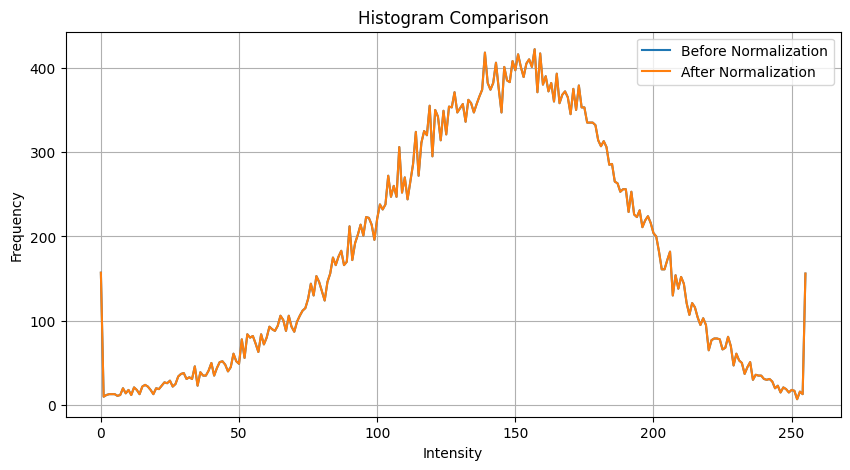

In [ ]:

hist1 = np.zeros(256, np.uint32)
hist2 = np.zeros(256, np.uint32)


for y in range(h):
    for x in range(w):
        pixel1 = int(noisy[y, x])
        hist1[pixel1] += 1

        pixel2 = int(imgNorm[y, x])
        hist2[pixel2] += 1


plt.figure(figsize=(10, 5))
plt.plot(hist1, label="Before Normalization")
plt.plot(hist2, label="After Normalization")

plt.title("Histogram Comparison")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.grid()
plt.show()

## 7. Affichage des images

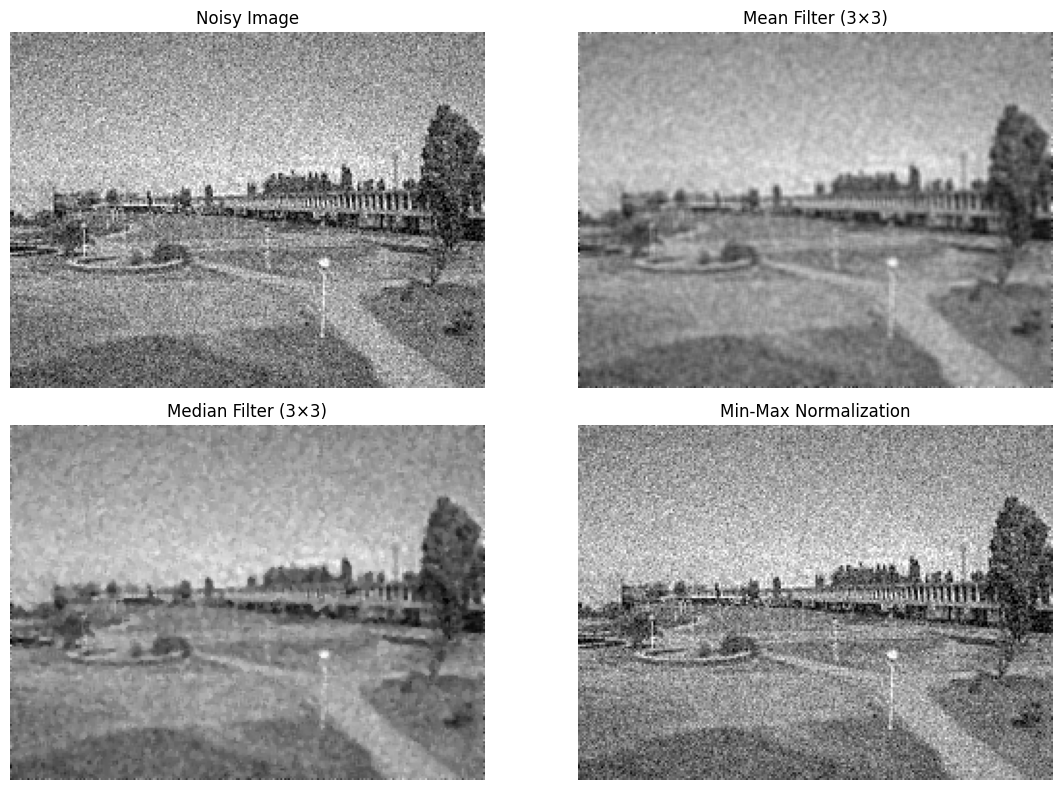

In [9]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(imgMoy, cmap="gray")
plt.title("Mean Filter (3×3)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(imgMed, cmap="gray")
plt.title("Median Filter (3×3)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(imgNorm, cmap="gray")
plt.title("Min-Max Normalization")
plt.axis("off")

plt.tight_layout()
plt.show()

## 8. À retenir

- Le **filtre moyen** remplace chaque pixel (sauf les bords) par la moyenne des 9 pixels de son voisinage 3×3.
- Le **filtre médian** trie les 9 pixels du voisinage et choisit la valeur centrale.
- La **normalisation Min-Max** transforme les intensités pour étendre leur plage de la valeur minimale à la valeur maximale vers l'intervalle 0–255.
- Les deux histogrammes comparent la distribution des intensités de `noisy` et de `imgNorm`.

Les filtres moyen et médian sont appliqués à `noisy`. La normalisation est également appliquée à `noisy`, indépendamment des deux filtres.
